In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ====================================================
# MODEL NAMES
# ====================================================

models = [
    "CustomCNN",
    "InceptionV3",
    "InceptionResNetV2",
    "DenseNet121",
    "MobileNetV2",
    "ResNet",
    "VGG16",
    "Xception"
    
]



accuracy_scores = [ 0.6820276379585266, 0.882488489151001, 0.8894008994102478,
                   0.9124423861503601, 0.8986175060272217, 0.4976958632469177, 0.8387096524238586, 0.9032257795333862,

                  ]
lmos_scores     = [0.2714275368501699, 0.3062778639842606, 0.47054512708251167,
                   0.5382236540147768, 0.5090714934086392, 0.4768866391550049,  0.5786457843125147, 0.6029103822117731,

                  ]



================ ETI ABLATION STUDY ================

            Model  Accuracy     LMOS  ETI (Full)  ETI w/o Accuracy  ETI w/o LMOS
        CustomCNN  0.682028 0.271428    0.476728          0.135714      0.341014
      InceptionV3  0.882488 0.306278    0.594383          0.153139      0.441244
InceptionResNetV2  0.889401 0.470545    0.679973          0.235273      0.444700
      DenseNet121  0.912442 0.538224    0.725333          0.269112      0.456221
      MobileNetV2  0.898618 0.509071    0.703844          0.254536      0.449309
           ResNet  0.497696 0.476887    0.487291          0.238443      0.248848
            VGG16  0.838710 0.578646    0.708678          0.289323      0.419355
         Xception  0.903226 0.602910    0.753068          0.301455      0.451613


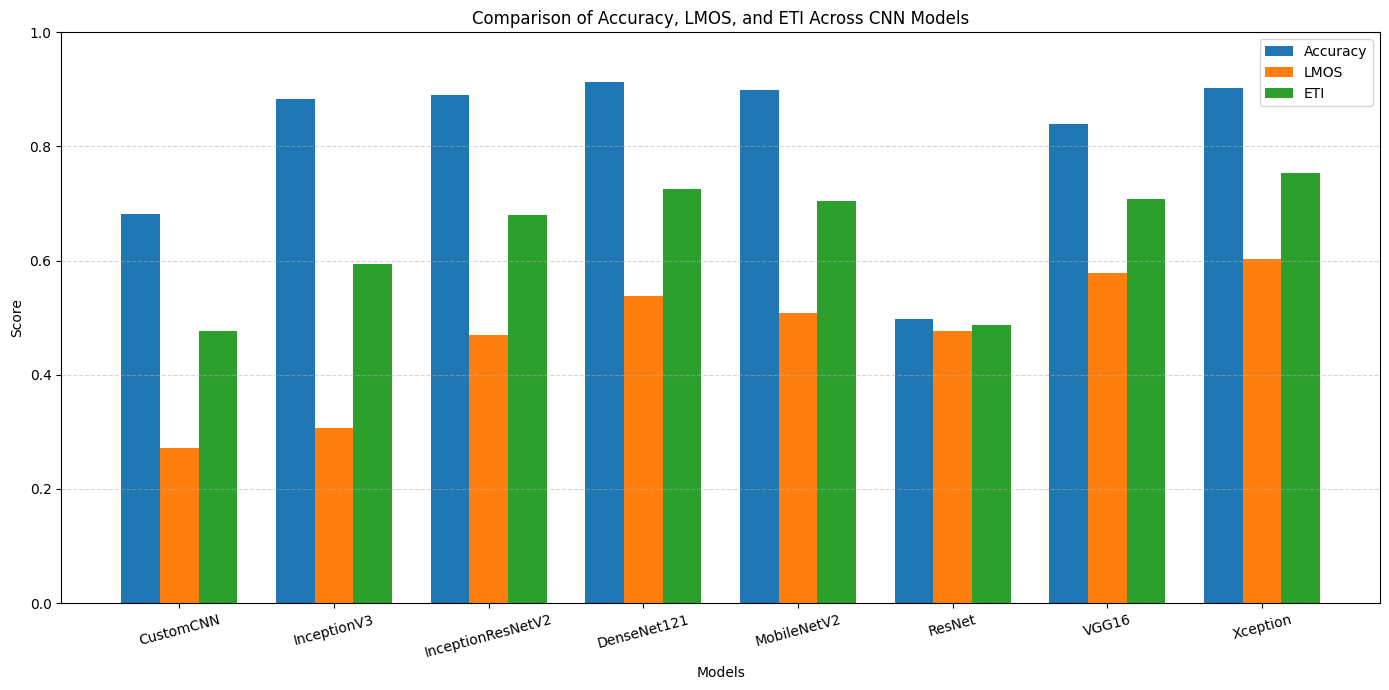


Plot saved as 'eti_components_plot.png'
Table saved as 'eti_ablation_study.csv'


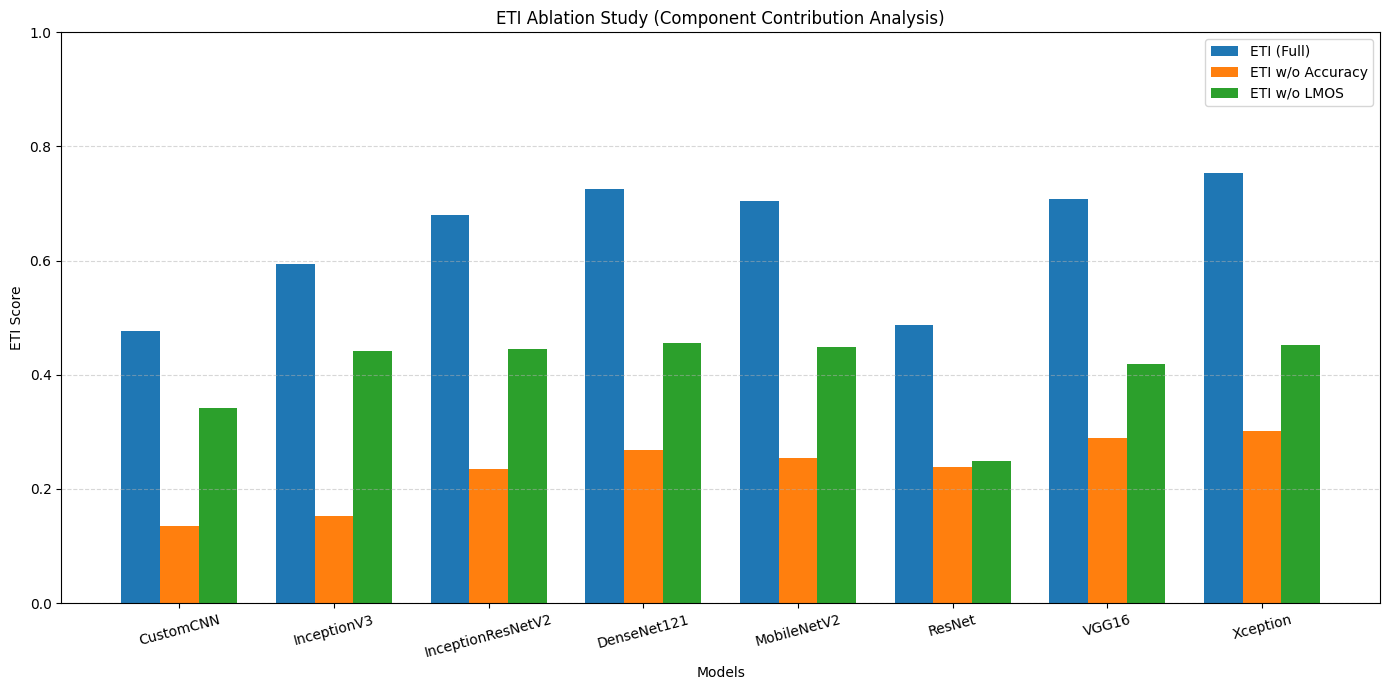

Ablation plot saved as 'eti_ablation_plot.png'


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



# ====================================================
# ETI CALCULATIONS
# ====================================================

eti_scores = [(a + l) / 2 for a, l in zip(accuracy_scores, lmos_scores)]

# Ablation Study
eti_without_accuracy = [l / 2 for l in lmos_scores]
eti_without_lmos     = [a / 2 for a in accuracy_scores]

# ====================================================
# CREATE ABLATION TABLE
# ====================================================

ablation_df = pd.DataFrame({
    "Model": models,
    "Accuracy": accuracy_scores,
    "LMOS": lmos_scores,
    "ETI (Full)": eti_scores,
    "ETI w/o Accuracy": eti_without_accuracy,
    "ETI w/o LMOS": eti_without_lmos
})

# ====================================================
# PRINT TABLE
# ====================================================

print("\n================ ETI ABLATION STUDY ================\n")
print(ablation_df.to_string(index=False))

# ====================================================
# PLOT SETUP
# ====================================================

x = np.arange(len(models))
width = 0.25

plt.figure(figsize=(14, 7))

# Accuracy Bars
plt.bar(
    x - width,
    accuracy_scores,
    width=width,
    label='Accuracy'
)

# LMOS Bars
plt.bar(
    x,
    lmos_scores,
    width=width,
    label='LMOS'
)

# ETI Bars
plt.bar(
    x + width,
    eti_scores,
    width=width,
    label='ETI'
)

# ====================================================
# LABELS & DESIGN
# ====================================================

plt.xticks(x, models, rotation=15)
plt.ylabel("Score")
plt.xlabel("Models")
plt.title("Comparison of Accuracy, LMOS, and ETI Across CNN Models")

plt.ylim(0.00, 1.00)

plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()

# ====================================================
# SAVE FIGURE
# ====================================================

plt.savefig(
    "eti_components_plot.png",
    dpi=600,
    bbox_inches='tight'
)

# ====================================================
# SAVE TABLE
# ====================================================

ablation_df.to_csv("eti_ablation_study.csv", index=False)

plt.show()

print("\nPlot saved as 'eti_components_plot.png'")
print("Table saved as 'eti_ablation_study.csv'")

# ====================================================
# ABLATION STUDY PLOT
# ====================================================

plt.figure(figsize=(14, 7))

x = np.arange(len(models))
width = 0.25

plt.bar(x - width, eti_scores, width=width, label="ETI (Full)")
plt.bar(x, eti_without_accuracy, width=width, label="ETI w/o Accuracy")
plt.bar(x + width, eti_without_lmos, width=width, label="ETI w/o LMOS")

plt.xticks(x, models, rotation=15)
plt.ylabel("ETI Score")
plt.xlabel("Models")
plt.title("ETI Ablation Study (Component Contribution Analysis)")

plt.ylim(0.00, 1.00)

plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()

# Save ablation plot
plt.savefig(
    "eti_ablation_plot.png",
    dpi=600,
    bbox_inches='tight'
)

plt.show()

print("Ablation plot saved as 'eti_ablation_plot.png'")